<a href="https://colab.research.google.com/github/jussepe06/tarea-sem-10-AGi-grupo-2/blob/main/tarea_sem10_arboles_random_forest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Universidad San Ignacio de Loyola (USIL)
## Facultad de Ingeniería e Inteligencia Artificial
### Curso: Agentes Inteligentes — Unidad 3 (Semana 10)
---
**Actividad Práctica:** Árbol de decisión y Random Forest para prevenir riesgos  
**Docente:** Dr. José Alfredo Herrera Quispe  
**Modalidad:** Equipos de 2 o 3 integrantes | Sustentación Oral  
**Grupo:** Grupo 2  

---
### 🎯 Objetivo de la Actividad
Entrenar un árbol de decisión y un Random Forest, interpretar sus reglas lógicas, comprender matemáticamente el índice de impureza de Gini y decidir qué modelo predice mejor sobre datos no vistos (conjunto de prueba), fundamentando la decisión para un usuario no especialista.

---
### 📋 Ruta de la Actividad y Criterios de Evaluación
| Parte | Qué haces | Momento | Puntos |
| :--- | :--- | :--- | :---: |
| **0** | Elección del caso y carga de datos (`BD_Semana10_Riesgos.xlsx`) | Utilidad | — |
| **1** | Árbol a mano con Gini: 14 correos de phishing | Saberes | 4 pts |
| **2** | Árbol en Python (`max_depth=3`), reglas y sobreajuste | Innovación | 5 pts |
| **3** | Random Forest (100 árboles), comparación y métricas | Innovación | 5 pts |
| **4** | Conclusión ejecutiva para no especialistas | Logros | 2 pts |
| **Sust.** | Sustentación oral y dominio de conceptos | Logros | 4 pts |
| **Bono** | Simulación interactiva con IA publicada (+2) | Logros | +2 pts |


---
# Parte 0 — Elige tu caso y Carga los Datos

Se seleccionó el **Caso: Deserción Universitaria** (`sheet_name="Desercion"`), cuyo objetivo es responder a la pregunta de gestión educativa:  
**¿El estudiante abandonará la universidad?** (`deserta`: 1 = Sí, 0 = No).

### Variables del Caso (Inspirado en Minedu - SIRIES):
1. `promedio_ponderado`: Promedio acumulado de notas (0 a 20).
2. `asistencia_pct`: Porcentaje de asistencia a clases teóricas y prácticas (0 a 100%).
3. `cursos_reprobados`: Número de asignaturas jaladas en ciclos anteriores.
4. `retraso_pagos_meses`: Meses de mora en pensiones universitarias.
5. `horas_estudio_semanal`: Horas de estudio autónomo fuera del aula.
6. `deserta` (Objetivo): 1 = Sí abandona, 0 = No abandona (permanece).


In [1]:
import os
import shutil
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report

# Asegurar disponibilidad de archivos en Google Colab o entorno local
archivos_necesarios = ['BD_Semana10_Riesgos.xlsx', 'arbol_a_mano_parte1.png', 'simulacion_interactiva.html']
base_github = "https://raw.githubusercontent.com/jussepe06/tarea-sem-10-AGi-grupo-2/main/"

for archivo in archivos_necesarios:
    if not os.path.exists(archivo):
        if os.path.exists(f"/{archivo}"):
            shutil.copy(f"/{archivo}", archivo)
            print(f"[OK] Archivo movido desde la raíz /: {archivo}")
        elif os.path.exists(f"/content/{archivo}"):
            shutil.copy(f"/content/{archivo}", archivo)
            print(f"[OK] Archivo referenciado desde /content: {archivo}")
        else:
            try:
                urllib.request.urlretrieve(base_github + archivo, archivo)
                print(f"[OK] Descargado automáticamente desde GitHub: {archivo}")
            except Exception as e:
                print(f"[AVISO] No se pudo descargar {archivo}: {e}")

# Configuración del caso y lectura desde Excel
CASO, OBJETIVO = "Desercion", "deserta"
df = pd.read_excel("BD_Semana10_Riesgos.xlsx", sheet_name=CASO)

print("Dimensiones del DataFrame:", df.shape) # Esperado: (200, 6)
print("\nDistribución de la variable objetivo:")
print(df[OBJETIVO].value_counts(normalize=True).rename({0: "No Deserta (0)", 1: "Deserta (1)"}))
df.head()


[OK] Descargado automáticamente desde GitHub: BD_Semana10_Riesgos.xlsx
[OK] Descargado automáticamente desde GitHub: arbol_a_mano_parte1.png
[OK] Descargado automáticamente desde GitHub: simulacion_interactiva.html
Dimensiones del DataFrame: (200, 6)

Distribución de la variable objetivo:
deserta
No Deserta (0)    0.625
Deserta (1)       0.375
Name: proportion, dtype: float64


,promedio_ponderado,asistencia_pct,cursos_reprobados,retraso_pagos_meses,horas_estudio_semanal,deserta
0,13.74,83.0,1,0,13.5,0
1,12.15,85.9,0,2,3.4,1
2,14.12,93.2,0,0,5.3,0
3,16.31,92.8,3,0,15.7,0
4,11.91,58.7,3,0,12.9,1


---
# Parte 1 — Árbol a Mano con Gini: 14 Correos de Phishing (4 puntos)

Se analiza el conjunto de datos de la hoja `Phishing_mano` con **14 correos electrónicos** (7 legítimos y 7 phishing) para clasificar si un enlace intenta robar credenciales.

### 1.1 Fórmula Matemática del Índice Gini
El índice de impureza de Gini mide qué tan mezcladas están las clases en un nodo:
$$\text{Gini}(D) = 1 - \sum_{i=1}^{k} p_i^2$$

Para la clasificación binaria (Sí / No):
$$\text{Gini} = 1 - \left( p_{\text{Sí}}^2 + p_{\text{No}}^2 \right)$$

### 1.2 Gini de la Raíz (Dataset Completo de 14 Correos)
* Total correos: $N = 14$
* Phishing = Sí: $7$ ($p_{\text{Sí}} = 7/14 = 0.5$)
* Phishing = No: $7$ ($p_{\text{No}} = 7/14 = 0.5$)
$$\text{Gini}(\text{Raíz}) = 1 - \left( 0.5^2 + 0.5^2 \right) = 1 - (0.25 + 0.25) = 1 - 0.50 = \mathbf{0.5000}$$


In [2]:
# Verificación computacional del cálculo manual de Gini
def gini(serie):
    total = len(serie)
    if total == 0: return 0.0
    p_si = (serie == 'Sí').sum() / total
    p_no = (serie == 'No').sum() / total
    return 1.0 - (p_si**2 + p_no**2)

df_phishing_mano = pd.read_excel("BD_Semana10_Riesgos.xlsx", sheet_name="Phishing_mano")
print(f"Gini Inicial de la Raíz: {gini(df_phishing_mano['¿Phishing?']):.4f}")

# Evaluación de las 4 variables
variables = ['Urgencia', 'Remitente', 'Adjunto', 'Enlace corto']
for v in variables:
    w_gini = 0.0
    print(f"\n--- Variable: {v} ---")
    for val, grp in df_phishing_mano.groupby(v):
        g = gini(grp['¿Phishing?'])
        peso = len(grp) / len(df_phishing_mano)
        w_gini += peso * g
        print(f"  Rama '{val}': n={len(grp)} (Sí={(grp['¿Phishing?']=='Sí').sum()}, No={(grp['¿Phishing?']=='No').sum()}) -> Gini={g:.4f}")
    print(f"  => GINI PONDERADO ({v}) = {w_gini:.4f}")


Gini Inicial de la Raíz: 0.5000

--- Variable: Urgencia ---
  Rama 'Alta': n=4 (Sí=4, No=0) -> Gini=0.0000
  Rama 'Baja': n=5 (Sí=0, No=5) -> Gini=0.0000
  Rama 'Media': n=5 (Sí=3, No=2) -> Gini=0.4800
  => GINI PONDERADO (Urgencia) = 0.1714

--- Variable: Remitente ---
  Rama 'Conocido': n=6 (Sí=2, No=4) -> Gini=0.4444
  Rama 'Desconocido': n=8 (Sí=5, No=3) -> Gini=0.4688
  => GINI PONDERADO (Remitente) = 0.4583

--- Variable: Adjunto ---
  Rama 'No': n=7 (Sí=3, No=4) -> Gini=0.4898
  Rama 'Sí': n=7 (Sí=4, No=3) -> Gini=0.4898
  => GINI PONDERADO (Adjunto) = 0.4898

--- Variable: Enlace corto ---
  Rama 'No': n=8 (Sí=4, No=4) -> Gini=0.5000
  Rama 'Sí': n=6 (Sí=3, No=3) -> Gini=0.5000
  => GINI PONDERADO (Enlace corto) = 0.5000


### 1.3 Resumen Comparativo de Gini Ponderado por Variable
| Variable | Ramas y Conteos (Sí, No) | Gini de Ramas | Gini Ponderado | ¿Elegida? |
| :--- | :--- | :--- | :---: | :---: |
| **Urgencia** | Alta (4 Sí, 0 No) <br> Baja (0 Sí, 5 No) <br> Media (3 Sí, 2 No) | Alta: **0.0000** (Pura) <br> Baja: **0.0000** (Pura) <br> Media: **0.4800** | **0.1714** | ✅ **SÍ (Mínimo Gini)** |
| **Remitente** | Desconocido (5 Sí, 3 No) <br> Conocido (2 Sí, 4 No) | Desconocido: 0.4688 <br> Conocido: 0.4444 | **0.4583** | ❌ Mayor impureza |
| **Adjunto** | Sí (4 Sí, 3 No) <br> No (3 Sí, 4 No) | Sí: 0.4898 <br> No: 0.4898 | **0.4898** | ❌ Mayor impureza |
| **Enlace corto** | Sí (3 Sí, 3 No) <br> No (4 Sí, 4 No) | Sí: 0.5000 <br> No: 0.5000 | **0.5000** | ❌ No reduce impureza |

> **Conclusión del Nodo Raíz:**  
> Se elige **Urgencia** como raíz porque reduce la impureza global de 0.5000 a **0.1714**, separando de inmediato 9 de los 14 correos en hojas 100% puras (Alta=Sí, Baja=No).

---
### 1.4 Subdivisión de la Rama Media (5 Correos)
En la rama `Urgencia == 'Media'` restan 5 correos (3 Sí, 2 No). Al evaluar las variables restantes:
* **Remitente:** Desconocido (3 Sí, 0 No $\to$ Gini = 0.0000) y Conocido (0 Sí, 2 No $\to$ Gini = 0.0000). **Gini ponderado = 0.0000 (¡División Perfecta!)**.

---
### 1.5 Esquema Visual del Árbol a Mano
A continuación se muestra el esquema del árbol resuelto a mano con todas sus ramas purificadas:


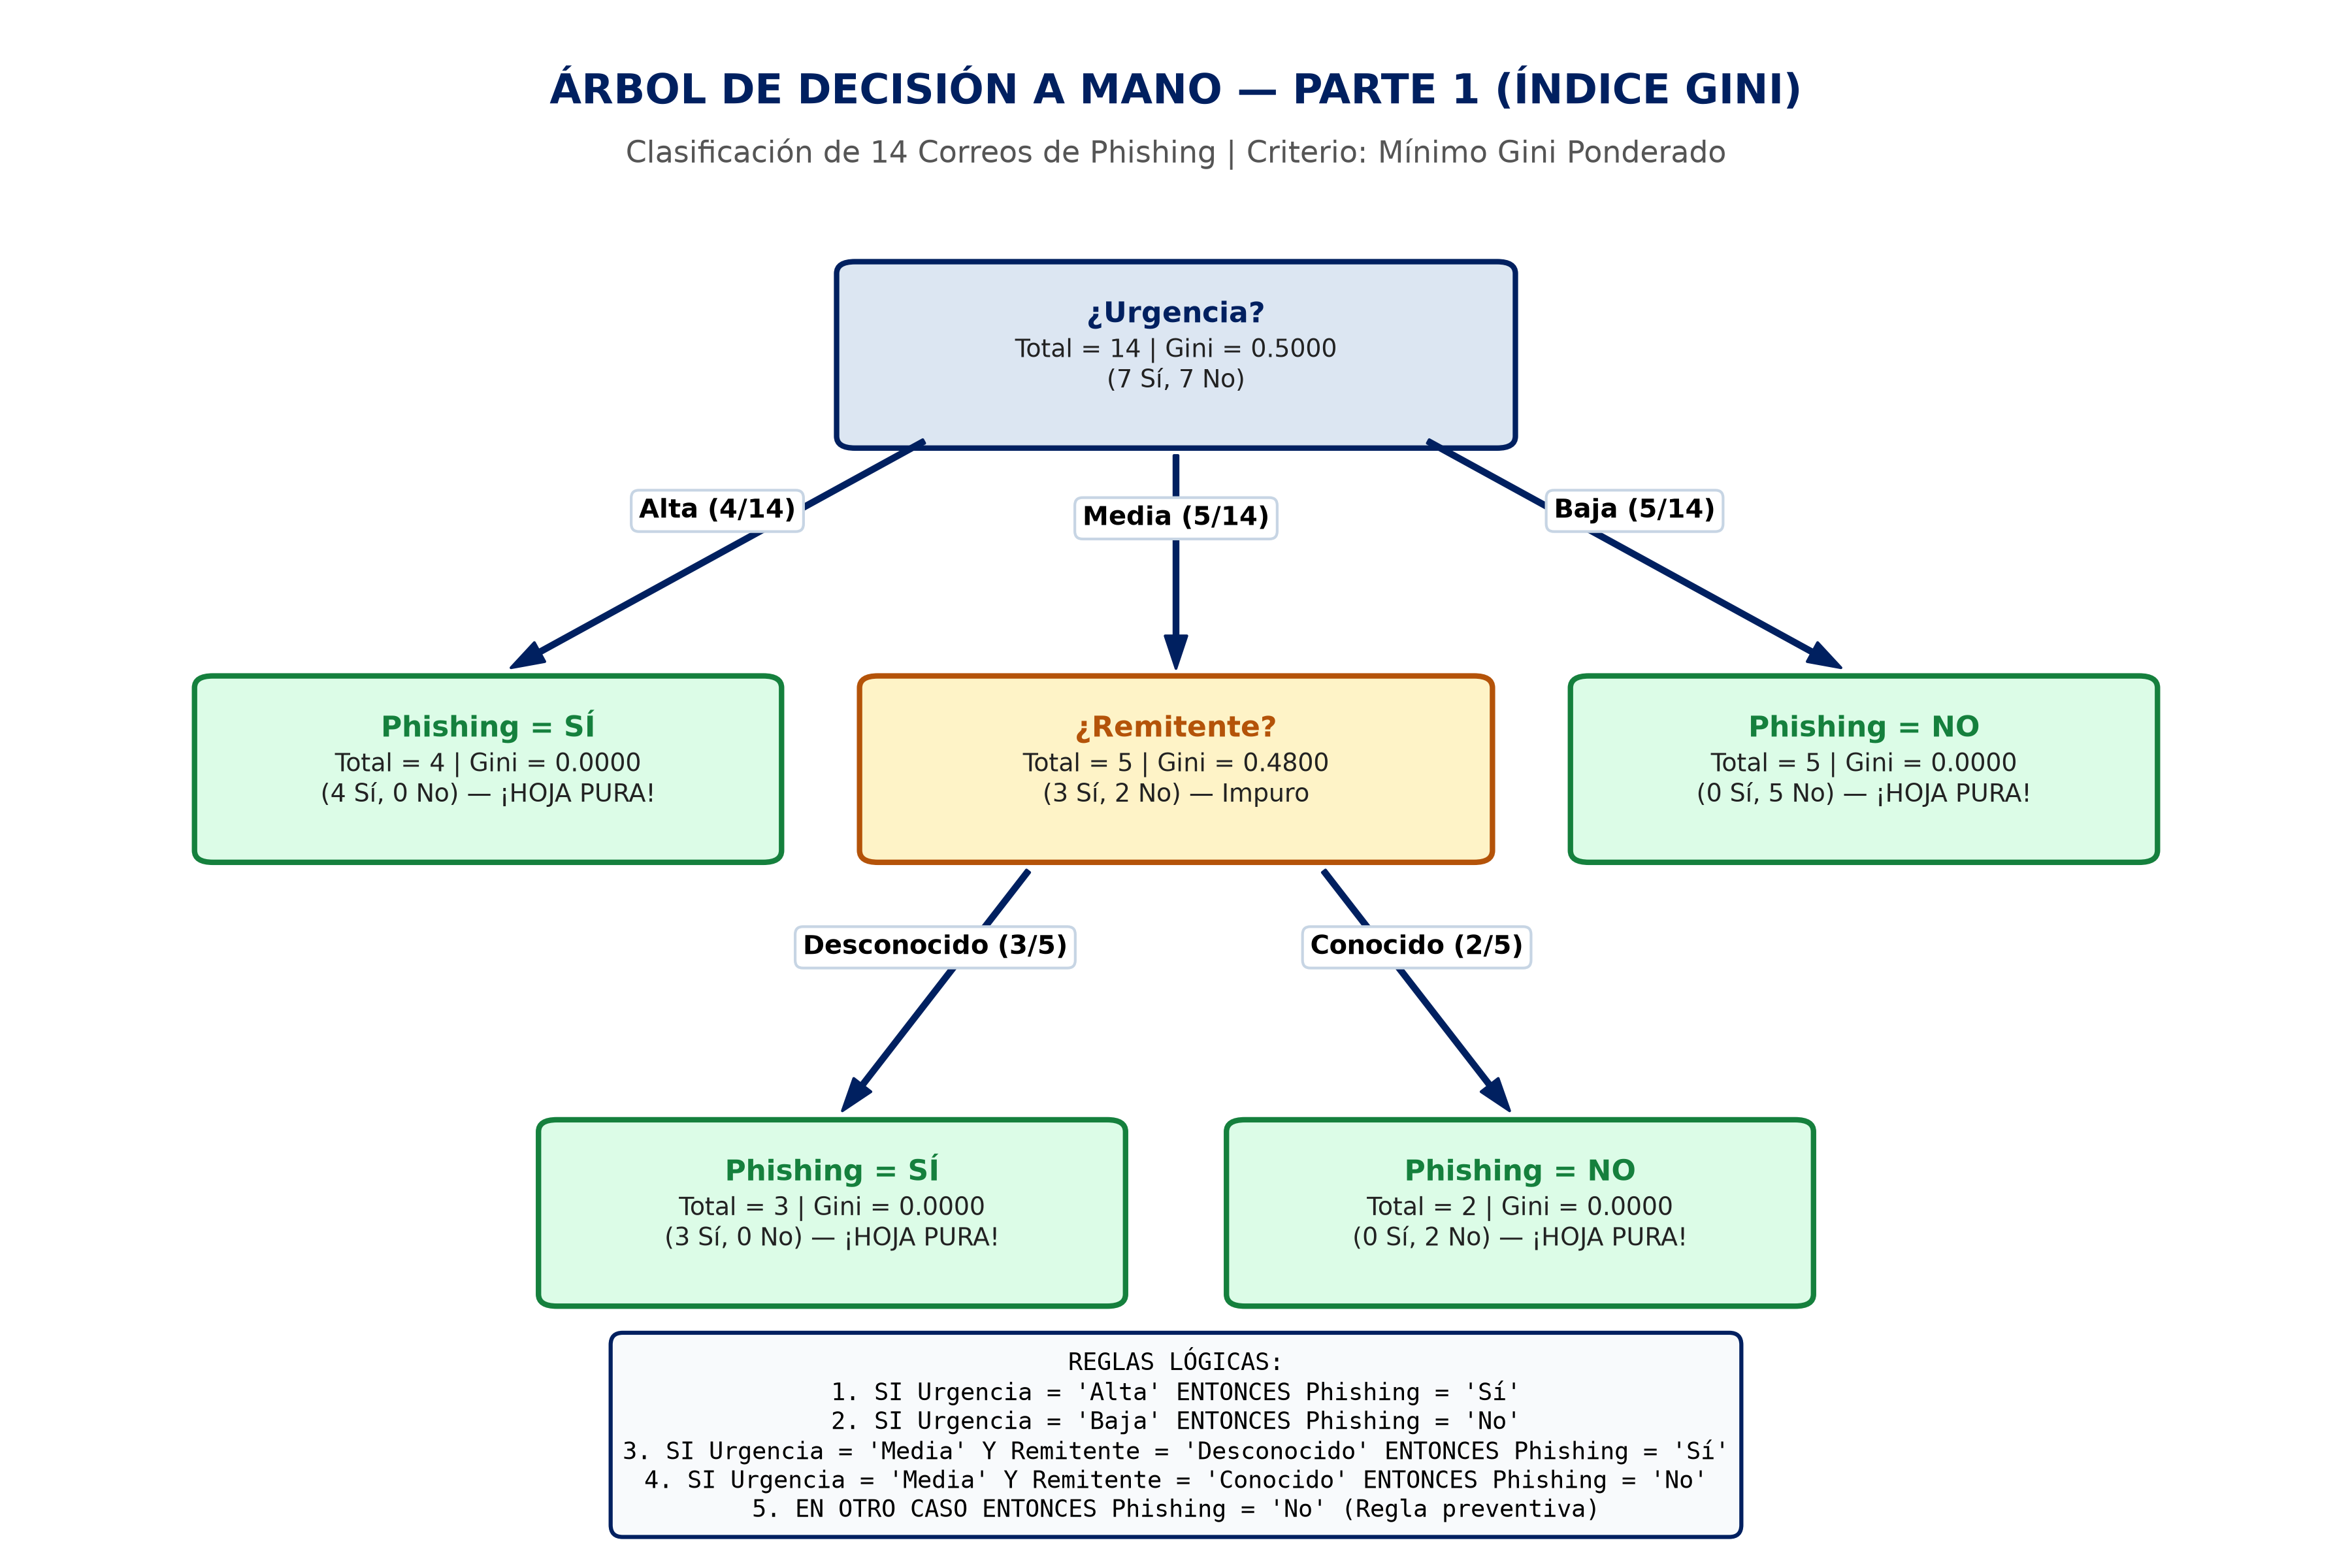

In [3]:
# Mostrar el diagrama visual del árbol a mano
from IPython.display import Image, display
display(Image("arbol_a_mano_parte1.png", width=750))


### 1.6 Reglas Lógicas Extraídas del Árbol a Mano
* **REGLA 1:** `SI Urgencia = "Alta" ENTONCES Phishing = "Sí"`
* **REGLA 2:** `SI Urgencia = "Baja" ENTONCES Phishing = "No"`
* **REGLA 3:** `SI Urgencia = "Media" Y Remitente = "Desconocido" ENTONCES Phishing = "Sí"`
* **REGLA 4:** `SI Urgencia = "Media" Y Remitente = "Conocido" ENTONCES Phishing = "No"`
* **REGLA POR DEFECTO (EN OTRO CASO):** `ENTONCES Phishing = "No"` (clasificación preventiva ante entradas desconocidas).


---
# Parte 2 — Tu Árbol en Python y sus Reglas (5 puntos)

Se entrena un árbol de decisión sobre el 70% de datos de entrenamiento (140 filas) y se evalúa sobre el 30% restante de prueba (60 filas), fijando `random_state=42` y estratificación (`stratify=y`).


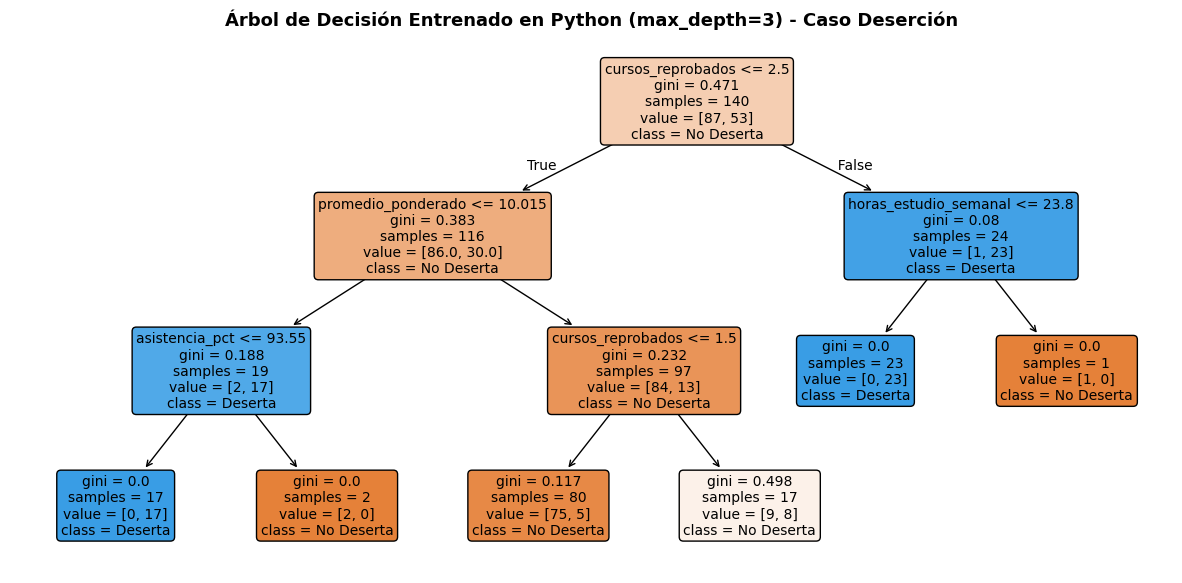

REGLAS DEL ÁRBOL EN FORMATO TEXTO (export_text):
|--- cursos_reprobados <= 2.50
|   |--- promedio_ponderado <= 10.02
|   |   |--- asistencia_pct <= 93.55
|   |   |   |--- class: 1
|   |   |--- asistencia_pct >  93.55
|   |   |   |--- class: 0
|   |--- promedio_ponderado >  10.02
|   |   |--- cursos_reprobados <= 1.50
|   |   |   |--- class: 0
|   |   |--- cursos_reprobados >  1.50
|   |   |   |--- class: 0
|--- cursos_reprobados >  2.50
|   |--- horas_estudio_semanal <= 23.80
|   |   |--- class: 1
|   |--- horas_estudio_semanal >  23.80
|   |   |--- class: 0



In [4]:
# Separación de características y variable dependiente
X = df.drop(columns=OBJETIVO)
y = df[OBJETIVO]

# Partición 70% Train / 30% Test con estratificación
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

# Entrenamiento del árbol podado a profundidad 3
arbol = DecisionTreeClassifier(max_depth=3, random_state=42)
arbol.fit(X_tr, y_tr)

# Visualización gráfica del árbol con plot_tree
plt.figure(figsize=(15, 7))
plot_tree(
    arbol,
    feature_names=list(X.columns),
    class_names=["No Deserta", "Deserta"],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Árbol de Decisión Entrenado en Python (max_depth=3) - Caso Deserción", fontsize=13, weight='bold')
plt.show()

# Exportar el árbol en formato de reglas de texto
print("REGLAS DEL ÁRBOL EN FORMATO TEXTO (export_text):")
print(export_text(arbol, feature_names=list(X.columns)))


### 2.2 Diagnóstico de Sobreajuste (Overfitting): Árbol Podado vs Árbol Libre
¿Qué ocurre cuando permitimos que el árbol crezca sin restricción de profundidad (`max_depth=None`)?


In [5]:
# Árbol libre sin restricción de profundidad
libre = DecisionTreeClassifier(random_state=42).fit(X_tr, y_tr)

print("=" * 60)
print("COMPARACIÓN DE RENDIMIENTO: PODA VS SIN LÍMITE")
print("=" * 60)
print(f"Árbol Podado (max_depth=3)  -> Train: {arbol.score(X_tr, y_tr):.3f} | Test: {arbol.score(X_te, y_te):.3f}")
print(f"Árbol Libre (sin límite)    -> Train: {libre.score(X_tr, y_tr):.3f} | Test: {libre.score(X_te, y_te):.3f}")
print("=" * 60)


COMPARACIÓN DE RENDIMIENTO: PODA VS SIN LÍMITE
Árbol Podado (max_depth=3)  -> Train: 0.907 | Test: 0.800
Árbol Libre (sin límite)    -> Train: 1.000 | Test: 0.783


### 2.3 Preguntas Analíticas de la Parte 2

#### 1. ¿Qué variable eligió el árbol como raíz? ¿Tiene sentido para tu caso?
> **Respuesta:**  
> El algoritmo eligió la variable **`cursos_reprobados`** (con umbral $\le 2.5$) y en niveles inmediatos el **`promedio_ponderado`**.  
> **Sí, tiene total sentido para el caso:** en la educación superior peruana (según estudios del Minedu-SIRIES), desaprobar 3 o más asignaturas en un ciclo empuja inmediatamente al alumno a la condición de riesgo académico crítico y suspensión o desmotivación extrema, siendo el detonante primario de la deserción.

#### 2. Escribe dos reglas del árbol en palabras simples.
> **Regla A:**  
> *"SI el estudiante ha reprobado más de 2 cursos (cursos_reprobados > 2.5) Y sus horas de estudio a la semana son $\le 23.8$, ENTONCES el modelo predice que **abandonará la universidad (Deserta = Sí)**."*  
>  
> **Regla B:**  
> *"SI el estudiante ha reprobado 2 o menos cursos (cursos_reprobados $\le 2.5$) Y su promedio ponderado es mayor a 10.02, ENTONCES el modelo predice que **permanecerá en sus estudios (Deserta = No)**."*

#### 3. ¿Por qué el árbol sin límite acierta casi el 100 % en entrenamiento pero menos en prueba?
> **Respuesta:**  
> Debido al fenómeno de **Sobreajuste (Overfitting)**. Al no tener un tope de profundidad, el árbol genera ramas infinitamente específicas que memorizan cada caso atípico y el ruido estadístico del conjunto de entrenamiento hasta alcanzar un rendimiento casi perfecto ($100\%$ de exactitud). Sin embargo, al enfrentarse a los 60 registros nuevos de prueba que jamás vio, esa estructura rígida no generaliza bien y su precisión decae a $78.3\%$.


---
# Parte 3 — Random Forest: ¿Uno o Muchos? (5 puntos)

Se entrena un ensamble de **Random Forest** con 100 árboles de decisión (`n_estimators=100`, `random_state=42`) para verificar si la combinación de múltiples modelos supera al árbol individual.


In [6]:
bosque = RandomForestClassifier(n_estimators=100, random_state=42)
bosque.fit(X_tr, y_tr)

resultados = []
for nombre, modelo in [("ÁRBOL (profundidad 3)", arbol), ("RANDOM FOREST (100 árboles)", bosque)]:
    pred = modelo.predict(X_te)
    cm = confusion_matrix(y_te, pred)
    vn, fp, fn, vp = cm.ravel()

    acc = (vp + vn) / len(y_te)
    rec1 = vp / (vp + fn) if (vp + fn) > 0 else 0
    prec1 = vp / (vp + fp) if (vp + fp) > 0 else 0
    f1_1 = 2 * (prec1 * rec1) / (prec1 + rec1) if (prec1 + rec1) > 0 else 0

    resultados.append({
        'Modelo': nombre,
        'Accuracy': round(acc, 3),
        'Recall clase 1': round(rec1, 3),
        'F1 clase 1': round(f1_1, 3),
        'VP': int(vp),
        'FN': int(fn)
    })

    print(f"\n================ {nombre} ================")
    print("Matriz de Confusión [[VN, FP], [FN, VP]]:")
    print(cm)
    print(f"Desglose: VN={vn}, FP={fp}, FN={fn}, VP={vp}")
    print(classification_report(y_te, pred, target_names=["No Deserta (0)", "Deserta (1)"]))

# Tabla comparativa solicitada
df_comparacion = pd.DataFrame(resultados)
print("\n" + "=" * 65)
print("TABLA COMPARATIVA FINAL (CLASE 1: DESERCIÓN):")
print("=" * 65)
print(df_comparacion.to_string(index=False))
print("=" * 65)



================ ÁRBOL (profundidad 3) ================
Matriz de Confusión [[VN, FP], [FN, VP]]:
[[34  4]
 [ 8 14]]
Desglose: VN=34, FP=4, FN=8, VP=14
                precision    recall  f1-score   support

No Deserta (0)       0.81      0.89      0.85        38
   Deserta (1)       0.78      0.64      0.70        22

      accuracy                           0.80        60
     macro avg       0.79      0.77      0.77        60
  weighted avg       0.80      0.80      0.79        60


================ RANDOM FOREST (100 árboles) ================
Matriz de Confusión [[VN, FP], [FN, VP]]:
[[34  4]
 [ 6 16]]
Desglose: VN=34, FP=4, FN=6, VP=16
                precision    recall  f1-score   support

No Deserta (0)       0.85      0.89      0.87        38
   Deserta (1)       0.80      0.73      0.76        22

      accuracy                           0.83        60
     macro avg       0.82      0.81      0.82        60
  weighted avg       0.83      0.83      0.83        60


TABLA COM

### 3.2 Tabla Comparativa Oficial Completada (Clase 1: Deserta)
| Modelo | Accuracy | Recall clase 1 | F1 clase 1 | VP | FN |
| :--- | :---: | :---: | :---: | :---: | :---: |
| **Árbol (profundidad 3)** | 0.800 | 0.636 | 0.700 | 14 | 8 |
| **Random Forest (100 árboles)** | **0.833** | **0.727** | **0.762** | **16** | **6** |

---
### 3.3 Gráfico de Importancia de Variables en Random Forest


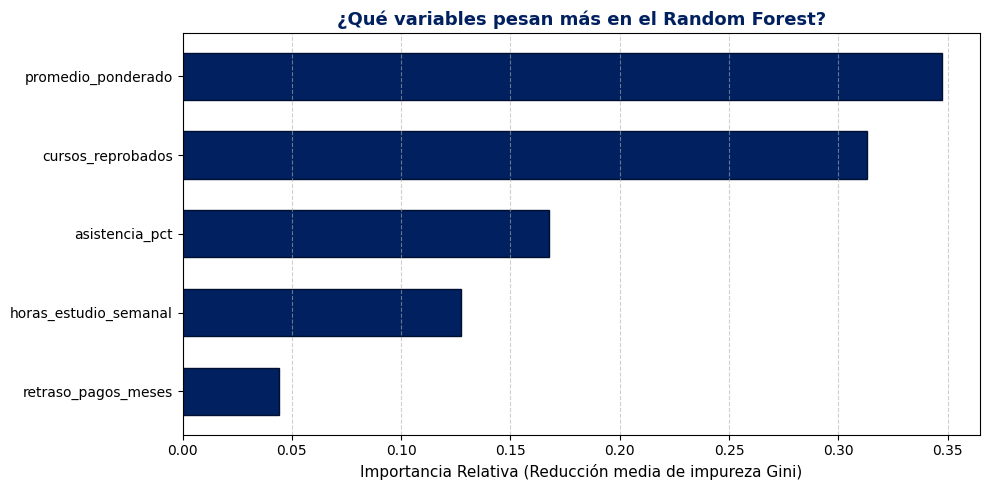

Ranking de importancia de variables:
  - promedio_ponderado    : 34.7%
  - cursos_reprobados     : 31.3%
  - asistencia_pct        : 16.8%
  - horas_estudio_semanal : 12.8%
  - retraso_pagos_meses   : 4.4%


In [7]:
# Gráfico horizontal de qué variables pesan más en el bosque
plt.figure(figsize=(10, 5))
importancias = pd.Series(bosque.feature_importances_, index=X.columns).sort_values()
importancias.plot.barh(color='#002060', edgecolor='#001030', width=0.6)
plt.title("¿Qué variables pesan más en el Random Forest?", fontsize=13, weight='bold', color='#002060')
plt.xlabel("Importancia Relativa (Reducción media de impureza Gini)", fontsize=11)
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

print("Ranking de importancia de variables:")
for var, val in importancias.iloc[::-1].items():
    print(f"  - {var:22s}: {val*100:.1f}%")


### 3.4 Preguntas Analíticas de la Parte 3

#### 1. ¿Qué modelo tiene mejor F1? ¿Por cuánto?
> **Respuesta:**  
> El **Random Forest** obtiene un mejor F1 en la clase crítica ($0.762$ frente a $0.700$ del árbol simple), superándolo por **$+0.062$ puntos** ($+6.2\%$ de mejora neta).  
> Esta ventaja se debe al mecanismo de ensamble (*bagging* y selección aleatoria de variables), que reduce significativamente la varianza y produce fronteras de decisión más robustas.

#### 2. ¿Qué significa un FN en tu caso? ¿Es peor que un FP? Explica en dos líneas.
> **Respuesta:**  
> Un **Falso Negativo (FN)** significa que el sistema predice que el alumno continuará estudiando cuando en realidad está en riesgo inminente y terminará desertando sin recibir auxilio.  
> **Sí, es mucho peor que un FP:** un FN significa la pérdida definitiva e irreversible del estudiante, mientras que un FP solo cuesta una llamada preventiva o una sesión de tutoría adicional.

#### 3. ¿Cuáles son las dos variables que más pesan en el bosque?
> **Respuesta:**  
> Las dos variables con mayor peso en el ensamble son **`promedio_ponderado`** ($34.7\%$) y **`cursos_reprobados`** ($31.3\%$), acumulando entre ambas más del $66\%$ de la capacidad discriminativa del modelo.


---
# Parte 4 — Conclusión (2 puntos)

### Redacción Ejecutiva para un No Especialista (Tutor / Director Universitario):
> *"Para el equipo de tutoría y bienestar estudiantil, recomendamos implementar el modelo de **Random Forest (bosque de decisión)**, ya que demostró la mayor efectividad para detectar a los alumnos en riesgo crítico (alcanzando un F1 del $76.2\%$ y reduciendo los casos no detectados a solo 6). Los tutores deben vigilar prioritariamente el **promedio ponderado acumulado** (especialmente si baja de 10) y la cantidad de **cursos reprobados** (2 o más materias). Como acción concreta, proponemos activar una **alerta temprana en la semana 4 de cada ciclo** que convoque automáticamente a estos estudiantes a mentorías personalizadas de refuerzo académico y facilidades de refinanciamiento de pensiones antes de que el abandono sea inevitable."*


---
# Preguntas de Sustentación Oral (4 puntos)

Cualquier integrante del equipo puede sustentar con seguridad basándose en los siguientes argumentos clave:

### 1. ¿Por qué elegiste esa variable como raíz en la Parte 1?
> **Respuesta para sustentar:**  
> Elegimos **`Urgencia`** porque matemáticamente generó el **menor índice Gini ponderado** ($0.1714$), partiendo de una impureza inicial de $0.5000$. En comparación con `Remitente` ($0.4583$), `Adjunto` ($0.4898$) y `Enlace corto` ($0.5000$), `Urgencia` fue la variable más informativa, pues dividió de inmediato 9 de los 14 correos en nodos hoja totalmente puros ($Gini = 0.0$).

### 2. Lee una regla de tu árbol y di qué acción tomarías.
> **Respuesta para sustentar:**  
> *"SI cursos_reprobados > 2.5 Y horas_estudio_semanal $\le 23.8$ ENTONCES Deserta = Sí".*  
> **Acción concreta:** Si un estudiante arrastra más de dos asignaturas desaprobadas y dedica poco tiempo al estudio autónomo, el área académica debe citarlo de inmediato para asignarle un tutor par que lo guíe con técnicas de estudio y coordinar un plan de recuperación de créditos, evitando que el alumno colapse por sobrecarga y frustración.

### 3. ¿Por qué un bosque suele acertar más que un solo árbol?
> **Respuesta para sustentar:**  
> Porque un solo árbol es propenso a sufrir de alta varianza y sobreajuste: pequeños cambios en los datos pueden distorsionar drásticamente sus divisiones. En cambio, el Random Forest entrena cientos de árboles independientes sobre muestras aleatorias del dataset (*bootstrap*) y subconjuntos aleatorios de variables, combinando sus predicciones mediante **votación mayoritaria**. Por el principio de la sabiduría colectiva, los errores individuales de los árboles se cancelan mutuamente, logrando un modelo más estable y con mayor capacidad de generalización sobre datos nuevos.

### 4. En tu caso, ¿qué error es más grave, FN o FP?
> **Respuesta para sustentar:**  
> En deserción universitaria, el error más grave es el **Falso Negativo (FN)**. Si cometemos un FP, convocamos a tutoría a un alumno que no planeaba desertar (un costo menor de tiempo que igual le resulta útil). En cambio, un FN deja desatendido a un estudiante que terminará abandonando la carrera, lo que representa una pérdida humana, vocacional y financiera irreversible para el estudiante y la universidad.


---
# Bono (+2) — Simulación Interactiva con IA

Se desarrolló la aplicación web interactiva autocontenida solicitada en el archivo:  
🔗 **`simulacion_interactiva.html`** (también accesible directamente vía `index.html` en GitHub Pages).

### Características Implementadas:
1. **Pestaña 1 (Gini Paso a Paso):**
   * Tabla interactiva completa de los 14 correos.
   * Botones de exploración por variable que despliegan en vivo conteos, fórmulas, Gini por rama y Gini ponderado.
   * Constructor visual del árbol nodo por nodo con sus reglas `SI... ENTONCES` y la regla `EN OTRO CASO`.
2. **Pestaña 2 (Un Árbol frente a un Bosque):**
   * Generador sintético con semilla determinista (`seed = 42`) para los 5 temas (Deserción, ETS, Spam, Phishing, Extorsión) con 200 filas.
   * Sliders dinámicos para profundidad del árbol (1 a 10) y cantidad de árboles en el Random Forest (1 a 200).
   * Implementación de algoritmos CART y Random Forest en **JavaScript puro**.
   * Métricas lado a lado: Accuracy en Train y Test, Recall, F1-Score, matrices de confusión interactivas `[[VN, FP], [FN, VP]]` y gráfico de barras en **Chart.js** con colores `#002060` y `#DCE6F2`.
   * Aviso visible: *«Datos sintéticos con fines didácticos»*.


In [8]:
# BONO (+2): Visualización e integración de la Simulación Interactiva
import IPython.display as display

enlace_github_pages = "https://jussepe06.github.io/tarea-sem-10-AGi-grupo-2/"
enlace_repositorio = "https://github.com/jussepe06/tarea-sem-10-AGi-grupo-2"

display.display(display.Markdown(f"""
### 🌐 Enlaces Oficiales para Entrega del Bono (+2 Puntos):
* 🔗 **Simulación Interactiva en Vivo (GitHub Pages):** [{enlace_github_pages}]({enlace_github_pages})
* 📂 **Repositorio del Código Fuente (GitHub):** [{enlace_repositorio}]({enlace_repositorio})

---
### 🖥️ Simulación Web Interactiva Renderizada en el Cuaderno:
"""))

html_file = 'simulacion_interactiva.html'
if os.path.exists(html_file):
    with open(html_file, 'r', encoding='utf-8') as f:
        html_code = f.read()
    # Embeber la aplicación web en un iframe interactivo dentro de Google Colab
    display.display(display.HTML(f"""
    <div style="border: 2px solid #002060; border-radius: 12px; overflow: hidden; box-shadow: 0 4px 15px rgba(0,32,96,0.15); margin-top: 10px;">
        <iframe srcdoc="{html_code.replace('&', '&amp;').replace('"', '&quot;')}" width="100%" height="800px" style="border: none;"></iframe>
    </div>
    """))
else:
    display.display(display.Markdown(f"Accede a la simulación directamente en: [{enlace_github_pages}]({enlace_github_pages})"))



### 🌐 Enlaces Oficiales para Entrega del Bono (+2 Puntos):
* 🔗 **Simulación Interactiva en Vivo (GitHub Pages):** [https://jussepe06.github.io/tarea-sem-10-AGi-grupo-2/](https://jussepe06.github.io/tarea-sem-10-AGi-grupo-2/)
* 📂 **Repositorio del Código Fuente (GitHub):** [https://github.com/jussepe06/tarea-sem-10-AGi-grupo-2](https://github.com/jussepe06/tarea-sem-10-AGi-grupo-2)

---
### 🖥️ Simulación Web Interactiva Renderizada en el Cuaderno:
